<a href="https://colab.research.google.com/github/bahaali273/COMP9200-AI-vs-Traditional-Intrusion-Analysis/blob/main/notebooks/01_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np

print("COMP 9200 - Cybersecurity Research Project")
print("Python environment ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


COMP 9200 - Cybersecurity Research Project
Python environment ready!
Pandas: 2.2.3
NumPy: 2.4.6


In [2]:

from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Dataset location
data_path = '/content/drive/MyDrive/Dataset/'

# Load training and testing datasets
train_df = pd.read_csv(data_path + 'UNSW_NB15_training-set.csv')
test_df = pd.read_csv(data_path + 'UNSW_NB15_testing-set.csv')

# Check dataset dimensions
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)


Mounted at /content/drive
Training dataset: (175341, 45)
Testing dataset: (82332, 45)


In [3]:

# Display the first five records and check the network traffic records
train_df.head()


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [4]:
# Check the distribution of normal and attack traffic
# how many records represent normal traffic and how many represent malicious traffic?

# Count normal and attack records
print("Training dataset - Traffic distribution")
print(train_df['label'].value_counts())

# Calculate percentages
print("\nTraffic distribution (%)")
print(train_df['label'].value_counts(normalize=True) * 100)

# Count different attack categories
print("\nAttack categories")
print(train_df['attack_cat'].value_counts())



Training dataset - Traffic distribution
label
1    119341
0     56000
Name: count, dtype: int64

Traffic distribution (%)
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

Attack categories
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64



## Initial Findings — Class Distribution

The UNSW-NB15 training dataset contains 175,341 records.

- Normal traffic: 56,000 records (31.94%)
- Malicious traffic: 119,341 records (68.06%)
- Number of attack categories: 9

The dataset exhibits class imbalance, with malicious traffic
representing approximately 68% of the training records.

Generic (40,000) and Exploits (33,393) are the most
frequent attack categories, while Worms (130) is the least
frequent.

These observations will inform subsequent statistical
analysis and the evaluation of AI-assisted findings.


In [5]:

# Data Quality Assessment and preprocessing

print("=== TRAINING DATASET ===")

# Check missing values
missing_train = train_df.isnull().sum()
print("\nTotal missing values:", missing_train.sum())
print("Columns with missing values:")
print(missing_train[missing_train > 0])

# Check duplicate records (excluding record ID)
duplicate_train = train_df.drop(
    columns=['id']
).duplicated().sum()

print("\nDuplicate records:", duplicate_train)

# Check feature data types
print("\nData types:")
print(train_df.dtypes.value_counts())

print("\n=== TESTING DATASET ===")

missing_test = test_df.isnull().sum()
print("\nTotal missing values:", missing_test.sum())

duplicate_test = test_df.drop(
    columns=['id']
).duplicated().sum()

print("Duplicate records:", duplicate_test)
print("\nData types:")
print(test_df.dtypes.value_counts())


=== TRAINING DATASET ===

Total missing values: 0
Columns with missing values:
Series([], dtype: int64)

Duplicate records: 67601

Data types:
int64      30
float64    11
object      4
Name: count, dtype: int64

=== TESTING DATASET ===

Total missing values: 0
Duplicate records: 26387

Data types:
int64      30
float64    11
object      4
Name: count, dtype: int64


dur -> Compare connection durations

sbytes -> Compare outgoing traffic volume

dbytes -> Compare incoming traffic volume

spkts -> Compare source packet counts

dpkts -> Compare destination packet counts

label -> Separate normal and malicious traffic

attack_cat -> Explore different attack categories

In [6]:
# Feature selection and preprocessing

# Select research features

selected_features = [
    'dur',
    'sbytes',
    'dbytes',
    'spkts',
    'dpkts',
    'label',
    'attack_cat'
]

# Create working copies without modifying original data
analysis_df = train_df[selected_features].copy()
validation_df = test_df[selected_features].copy()

# Check selected features and dataset shape
print("Selected features:")
print(analysis_df.columns.tolist())

print("\nAnalysis dataset shape:", analysis_df.shape)
print("Validation dataset shape:", validation_df.shape)

print("\nFirst five records:")
display(analysis_df.head())

# Check for invalid negative values
traffic_features = [
    'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts'
]

print("\nNegative values in traffic features:")
print((analysis_df[traffic_features] < 0).sum())


Selected features:
['dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'label', 'attack_cat']

Analysis dataset shape: (175341, 7)
Validation dataset shape: (82332, 7)

First five records:


,dur,sbytes,dbytes,spkts,dpkts,label,attack_cat
0,0.121478,258,172,6,4,0,Normal
1,0.649902,734,42014,14,38,0,Normal
2,1.623129,364,13186,8,16,0,Normal
3,1.681642,628,770,12,12,0,Normal
4,0.449454,534,268,10,6,0,Normal



Negative values in traffic features:
dur       0
sbytes    0
dbytes    0
spkts     0
dpkts     0
dtype: int64


In [7]:

# Descriptive Statistical Analysis
# How do network traffic characteristics differ between normal and malicious connections?

traffic_features = [
    'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts'
]

# Separate normal and malicious traffic
normal_df = analysis_df[analysis_df['label'] == 0]
attack_df = analysis_df[analysis_df['label'] == 1]

# Calculate descriptive statistics
summary = analysis_df.groupby('label')[traffic_features].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

print("=== DESCRIPTIVE STATISTICS ===")
display(summary.round(3))

# Compare median values
median_comparison = pd.DataFrame({
    'Normal Median': normal_df[traffic_features].median(),
    'Attack Median': attack_df[traffic_features].median()
})

median_comparison['Difference (Attack - Normal)'] = (
    median_comparison['Attack Median']
    - median_comparison['Normal Median']
)

print("\n=== MEDIAN COMPARISON ===")
display(median_comparison.round(3))


=== DESCRIPTIVE STATISTICS ===


dur                                    sbytes                     \
        count   mean median    std  min     max   count       mean  median   
label                                                                        
0       56000  1.017  0.039  4.859  0.0  60.000   56000   4105.703  1470.0   
1      119341  1.520  0.000  7.109  0.0  59.999  119341  11068.655   200.0   

                   ...  spkts                      dpkts                 \
              std  ... median      std min   max   count    mean median   
label              ...                                                    
0       11348.054  ...   12.0   57.344   1   656   56000  38.058   10.0   
1      211658.592  ...    2.0  160.975   1  9616  119341  10.013    0.0   

                           
           std min    max  
label                      
0      105.773   0   1716  
1      111.177   0  10974  

[2 rows x 30 columns]


=== MEDIAN COMPARISON ===


,Normal Median,Attack Median,Difference (Attack - Normal)
dur,0.039,0.0,-0.039
sbytes,1470.000,200.0,-1270.000
dbytes,1112.000,0.0,-1112.000
spkts,12.000,2.0,-10.000
dpkts,10.000,0.0,-10.000


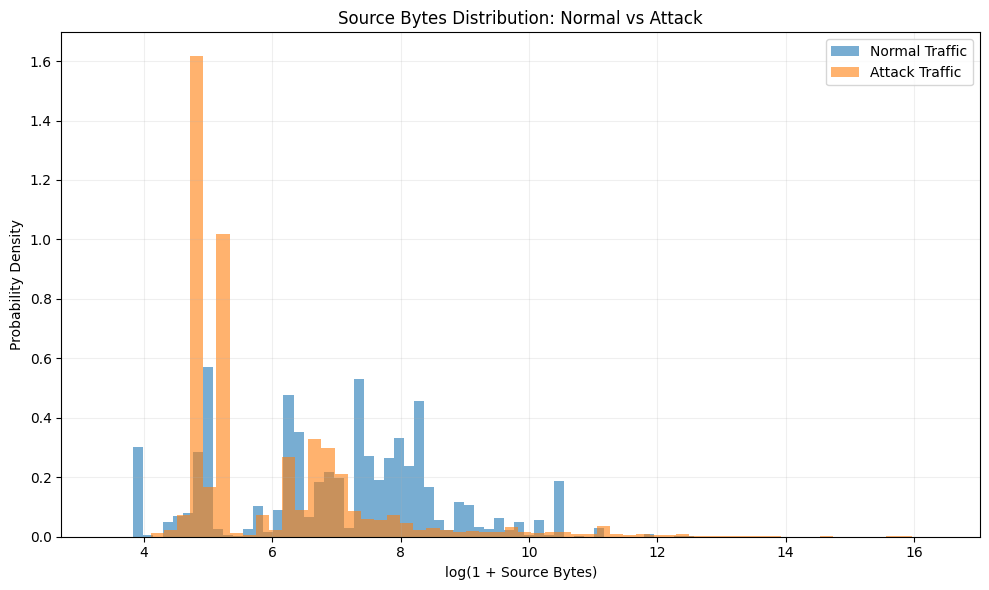

In [8]:

# Visualize source bytes distribution

import matplotlib.pyplot as plt
import numpy as np

normal_bytes = np.log1p(normal_df['sbytes'])
attack_bytes = np.log1p(attack_df['sbytes'])

plt.figure(figsize=(10, 6))

plt.hist(
    normal_bytes,
    bins=60,
    alpha=0.6,
    density=True,
    label='Normal Traffic'
)

plt.hist(
    attack_bytes,
    bins=60,
    alpha=0.6,
    density=True,
    label='Attack Traffic'
)

plt.xlabel('log(1 + Source Bytes)')
plt.ylabel('Probability Density')
plt.title('Source Bytes Distribution: Normal vs Attack')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()



* U statistic ->	Measures relative ranking between the two groups
* P-value ->	Evidence against the null
Hypothesis under test assumptions
* Rank-biserial -> effect	Direction and strength of the relative-ranking difference
* Decision->	Whether the result is statistically significant at α = 0.05

In [9]:

# Mann-Whitney U Test

from scipy.stats import mannwhitneyu

normal_values = normal_df['sbytes'].to_numpy()
attack_values = attack_df['sbytes'].to_numpy()

# Compare the distributions
u_stat, p_value = mannwhitneyu(
    attack_values,
    normal_values,
    alternative='two-sided',
    method='asymptotic'
)

# Common-language effect estimate
prob_superiority = u_stat / (
    len(attack_values) * len(normal_values)
)

# Rank-biserial effect size
rank_biserial = 2 * prob_superiority - 1

print("=== MANN-WHITNEY U TEST ===")
print(f"U statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.6e}")
print(f"Rank-biserial effect size: {rank_biserial:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")


=== MANN-WHITNEY U TEST ===
U statistic: 1960253092.50
P-value: 0.000000e+00
Rank-biserial effect size: -0.4134
Decision: Reject H0


The Mann–Whitney U test identified a statistically significant difference in source-byte distributions between normal and malicious traffic (U = 1,960,253,092.5, p < 0.001). The rank-biserial effect size (r = −0.4134) indicates that malicious traffic tends to exhibit lower source-byte values. However, potential dependencies and repeated observations limit the generalizability of this result.

In [10]:
# Compare different attack categories
# Do different types of cyberattack exhibit different network traffic patterns?


# Attack Category Analysis

# Include only malicious records
attack_only = analysis_df[analysis_df['label'] == 1]

# Calculate statistics for each attack category
category_summary = attack_only.groupby('attack_cat').agg(
    count=('sbytes', 'size'),
    mean_sbytes=('sbytes', 'mean'),
    median_sbytes=('sbytes', 'median'),
    median_duration=('dur', 'median'),
    median_spkts=('spkts', 'median')
)

# Sort by number of records
category_summary = category_summary.sort_values(
    by='count',
    ascending=False
)

print("=== ATTACK CATEGORY SUMMARY ===")
display(category_summary.round(3))


=== ATTACK CATEGORY SUMMARY ===


,count,mean_sbytes,median_sbytes,median_duration,median_spkts
attack_cat,,,,,
Generic,40000,396.043,114.0,0.000,2.0
Exploits,33393,28344.318,828.0,0.487,10.0
Fuzzers,18184,7286.696,914.0,0.617,10.0
DoS,12264,17272.011,200.0,0.000,2.0
Reconnaissance,10491,772.140,564.0,0.187,10.0
Analysis,2000,1029.638,200.0,0.000,2.0
Backdoor,1746,1834.583,200.0,0.000,2.0
Shellcode,1133,529.744,536.0,0.000,2.0
Worms,130,2403.438,1302.0,0.549,10.0


In [11]:

# Independent Testing Dataset Validation

from scipy.stats import mannwhitneyu
import pandas as pd

# Separate normal and attack traffic in testing data
test_normal = validation_df[validation_df['label'] == 0]
test_attack = validation_df[validation_df['label'] == 1]

print("=== TEST DATASET DISTRIBUTION ===")
print(validation_df['label'].value_counts())

# Compare median source bytes
print("\n=== TEST DATASET MEDIANS ===")
print("Normal median:", test_normal['sbytes'].median())
print("Attack median:", test_attack['sbytes'].median())

# Mann-Whitney U test
u_test, p_test = mannwhitneyu(
    test_attack['sbytes'],
    test_normal['sbytes'],
    alternative='two-sided',
    method='asymptotic'
)

# Calculate effect size
effect_test = (
    2 * u_test /
    (len(test_attack) * len(test_normal))
) - 1

print("\n=== TEST DATASET STATISTICAL TEST ===")
print(f"U statistic: {u_test:.2f}")
print(f"P-value: {p_test:.6e}")
print(f"Rank-biserial effect size: {effect_test:.4f}")

print("\n=== TRAINING VS TESTING COMPARISON ===")
print(f"Training effect size: {rank_biserial:.4f}")
print(f"Testing effect size: {effect_test:.4f}")


=== TEST DATASET DISTRIBUTION ===
label
1    45332
0    37000
Name: count, dtype: int64

=== TEST DATASET MEDIANS ===
Normal median: 974.0
Attack median: 200.0

=== TEST DATASET STATISTICAL TEST ===
U statistic: 504205113.00
P-value: 0.000000e+00
Rank-biserial effect size: -0.3988

=== TRAINING VS TESTING COMPARISON ===
Training effect size: -0.4134
Testing effect size: -0.3988


In [12]:

# Reproducibility and consistency checks

import pandas as pd
import numpy as np
import scipy

print("=== SOFTWARE VERSIONS ===")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

print("\n=== DATASET CHECKS ===")

assert train_df.shape == (175341, 45)
assert test_df.shape == (82332, 45)

assert train_df.isnull().sum().sum() == 0
assert test_df.isnull().sum().sum() == 0

assert set(train_df['label'].unique()) == {0, 1}
assert set(test_df['label'].unique()) == {0, 1}

assert len(analysis_df) == len(train_df)
assert len(validation_df) == len(test_df)

print("Dataset dimensions: PASS")
print("Missing values: PASS")
print("Binary labels: PASS")
print("Record preservation: PASS")

print("\n=== STATISTICAL CONSISTENCY ===")

assert rank_biserial < 0
assert effect_test < 0

assert attack_df['sbytes'].median() < normal_df['sbytes'].median()
assert test_attack['sbytes'].median() < test_normal['sbytes'].median()

print("Training effect direction: PASS")
print("Testing effect direction: PASS")
print("Median comparison: PASS")

print("\nAll reproducibility checks passed!")


=== SOFTWARE VERSIONS ===
Pandas: 2.2.3
NumPy: 2.4.6
SciPy: 1.16.3

=== DATASET CHECKS ===
Dataset dimensions: PASS
Missing values: PASS
Binary labels: PASS
Record preservation: PASS

=== STATISTICAL CONSISTENCY ===
Training effect direction: PASS
Testing effect direction: PASS
Median comparison: PASS

All reproducibility checks passed!



## Conclusion — Independent Statistical Analysis

This analysis examined the UNSW-NB15 network intrusion
detection dataset using Python, Pandas, NumPy, and SciPy.

The analysis included 175,341 training records and
82,332 testing records. Five numerical network traffic
features were selected for descriptive exploration.

### Key Findings

1. **Class Imbalance:** Malicious traffic represented
   68.06% of training records, compared with 31.94%
   normal traffic.

2. **Data Quality:** No missing values or negative
   values were identified in the selected traffic
   features. However, substantial numbers of repeated
   records were detected when excluding the ID column.

3. **Traffic Differences:** Malicious traffic exhibited
   lower median source-byte values than normal traffic
   in both dataset partitions.

4. **Statistical Evidence:** The Mann-Whitney U test
   indicated a statistically significant difference
   in source-byte distributions (p < 0.001).
   Rank-biserial effect sizes were -0.4134 for training
   and -0.3988 for testing.

5. **Attack Categories:** Traffic characteristics
   differed among attack categories, demonstrating
   that malicious network activity is not homogeneous.

### Limitations

The dataset contains repeated feature patterns and
potentially dependent network observations. These
factors may affect statistical inference.

The analysis is observational and does not establish
causal relationships or demonstrate the accuracy of
an intrusion detection classifier.

### Overall Conclusion

The analysis identified consistent differences in
source-byte distributions between normal and malicious
traffic across the training and testing datasets.

These findings provide a reproducible analytical
baseline for the subsequent comparison with
generative AI-assisted data analysis.
